Motunrayo Aduloju 
Assignment 1
AML 
October 10, 2026

Problem Statment 

Build an end-to-end machine learning project that predicts which deliveries will be late and warns the delivery team early enough to do something about it.

Demo of what I want to achieve 
Shipment MF1025 is predicted to arrive late.
- Expected delay: 2 hours
- Current status: In transit
- Recommended action: Review the route and notify the customer.

Main Objectives 

1. Understand the data
2. Build a prediction model
3. Send automatic alerts
4. Help prevent delay

Train of Though 

- Load the dataset (pandas) ✅
- Clean the dataset (pandas, numpy) ✅
- EDA (pandas, seaborn, matplot) ✅
- Feature engineering (Scikit-learn) ✅
- Test/Traning (train_test_split) ✅
- Model Building (Logistic Regrestion - Classifcation model vs XGboost)✅
- Evaulate the model of preciosn, acuracy, recall, F1 score ✅
- Explain predition featuers 
- Connect to slack 
- Test Test Test 

Step 1 - - Load the dataset (pandas)

In [27]:
%pip install seaborn

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('maplefreight_delivery_delay_dataset.csv')
display(df.head())
print(df.info())
df.shape


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

(6035, 23)

- Clean the dataset (pandas, numpy)
What am i looking for? Missing values, duplicate values etc 

In [28]:
missing_values = df.isnull().sum()
print("--- Missing Values Count ---")
print(missing_values[missing_values > 0])

--- Missing Values Count ---
driver_experience_years    210
weather_condition          150
traffic_index              121
fuel_cost_cad              240
dtype: int64


In [29]:
# Focus on handling missing values for columsn with missing values. I will use mean imputation for numercial values, use median for driver experience and mode for weather condition. 

# using median imputation for driver experience since it is numerical and can be skewed
df['driver_experience_years'] = df['driver_experience_years'].fillna(df['driver_experience_years'].median())
missing_values = df.isnull().sum()
print("--- Missing Values Count ---")
print(missing_values[missing_values > 0])

# Using mean imputation for traffic index and feul cost since they are numerical 
df['traffic_index'] = df['traffic_index'].fillna(df['traffic_index'].mean())
df['fuel_cost_cad'] = df['fuel_cost_cad'].fillna(df['fuel_cost_cad'].mean())
missing_values = df.isnull().sum()
print("--- Missing Values Count ---")
print(missing_values[missing_values > 0])

# Using mode imputation for weather condition since it is catergoracal 
most_frequent_weather = df['weather_condition'].mode()[0]
df['weather_condition'] = df['weather_condition'].fillna(most_frequent_weather)
missing_values = df.isnull().sum()
print("--- Missing Values Count ---")
print(missing_values[missing_values > 0])

# Handling duplicate rows. 
duplicates_count = df.duplicated().sum()
print(f"\nTotal duplicate rows: {duplicates_count}")
#drop duplicate rows, we have 32 rows that are duplicate, I dont't expect them to have much of an influence on the model, so I will drop them.
df = df.drop_duplicates()

#How do I handle outliers in the dataset? I will use the IQR method to detect and remove outliers for numerical columns.
numerical_cols_for_outliers = ['distance_km', 'weight_kg']
for col in numerical_cols_for_outliers:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Cap outliers to upper and lower bounds
    df[col] = np.clip(df[col], lower_bound, upper_bound)


    # I want to see what my dataset looks like after cleaning
display(df.head(100))

--- Missing Values Count ---
weather_condition    150
traffic_index        121
fuel_cost_cad        240
dtype: int64
--- Missing Values Count ---
weather_condition    150
dtype: int64
--- Missing Values Count ---
Series([], dtype: int64)

Total duplicate rows: 32


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.100,...,55.0,5.1,6.1,Fog,37.200000,0.291,1,146.390000,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.100,...,69.0,5.3,4.2,Snow,77.400000,0.236,0,155.070000,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.800,...,-13.0,1.4,2.8,Rain,36.500000,0.344,0,163.440000,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.200,...,-20.0,4.0,14.8,Fog,51.200000,0.491,2,180.696552,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,2471.825,...,28.0,2.9,1.6,Clear,82.700000,0.423,1,263.220000,13.49,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,SHP-102744,Montreal QC,Edmonton AB,NorthStar Carriers,Express,Bulk,Silver,3,627.0,559.600,...,41.0,24.9,4.1,Clear,66.000000,0.607,1,291.950000,11.14,0
96,SHP-102135,Montreal QC,Hamilton ON,MapleFreight Fleet,Economy,Hazardous,Silver,7,421.8,276.700,...,122.0,7.9,7.8,Rain,57.000000,0.879,1,119.250000,5.76,0
97,SHP-101334,Montreal QC,Montreal QC,PrairieLine,Economy,Fragile,Bronze,2,424.5,1361.700,...,1.0,8.7,3.5,Rain,78.000000,0.461,0,140.640000,5.66,0
98,SHP-102339,Toronto ON,Ottawa ON,QuebecExpress,Standard,General Freight,Silver,2,349.0,472.300,...,19.0,4.5,4.0,Clear,10.500000,0.116,2,211.060000,6.20,0


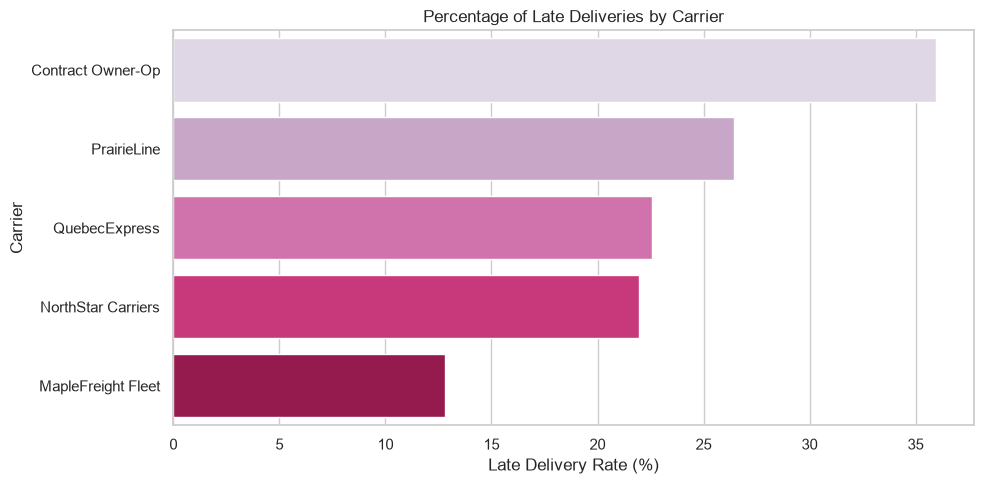

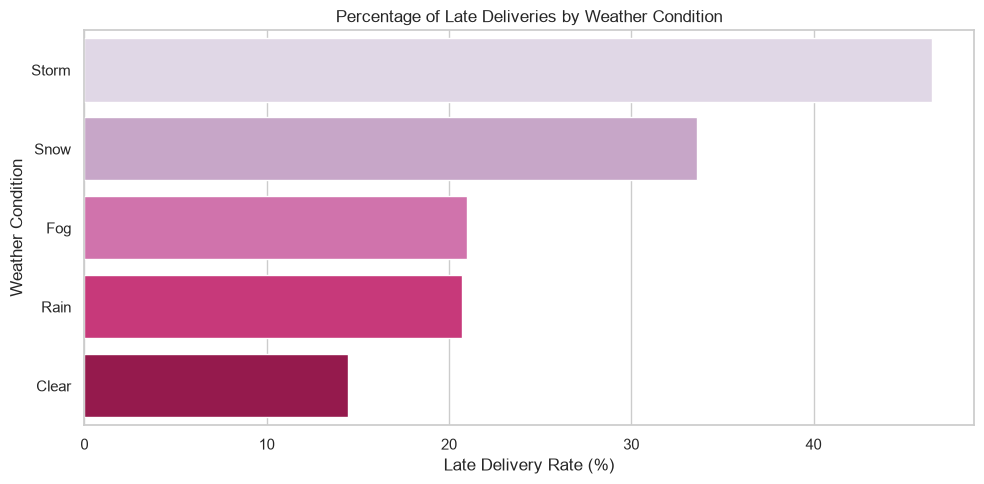

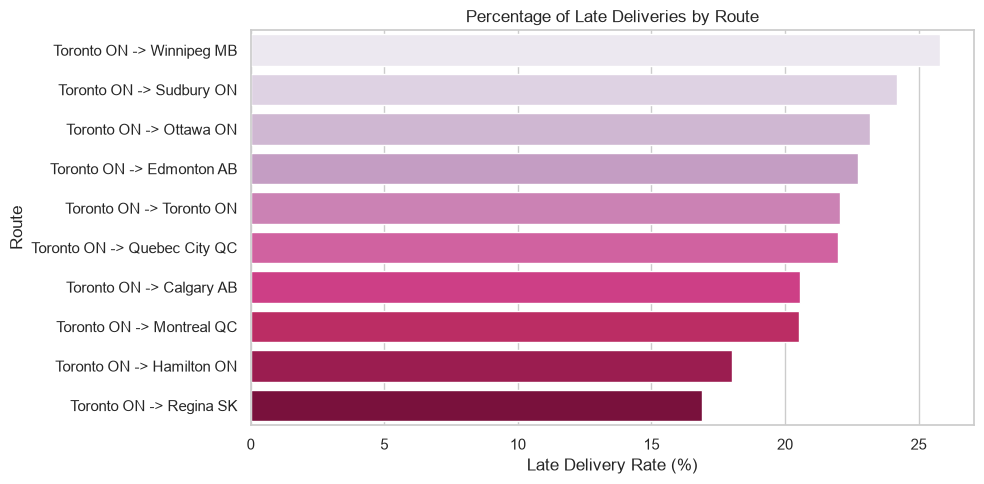

In [30]:
# Lets find some patterns 
# Late deliveries rate by the carrier 
# Late deliveries rate by weather - my bets is on snowy weather
# Late delivers rate by route - surely has to Tornoto, too much traffic. 

# set theme - clean, minialistic and pink 
sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams["figure.figsize"] = (12, 5)

# Let's determine the rate of late deliveries by carrier
def get_late_rate_df(column_name):
    rate_df = df.groupby(column_name)['delivered_late'].mean().reset_index()
    rate_df['delivered_late'] = rate_df['delivered_late'] * 100  
    return rate_df.sort_values(by='delivered_late', ascending=False)

carrier_late = get_late_rate_df('carrier')
plt.figure(figsize=(10, 5))
sns.barplot(data=carrier_late, x='delivered_late', y='carrier', palette='PuRd', hue='carrier', legend=False)

plt.title('Percentage of Late Deliveries by Carrier')
plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Carrier')
plt.tight_layout()
plt.show()

#Contract Owner-op need to check their logisitics, 35% is astronimical. But this is a good observation. I do find it intresting 
# I have to look into other patterns, such as if the weather places an impact or if it's the type of products they transport. 


# Let see the late delivery rate by weather condition
weather_late = get_late_rate_df('weather_condition')
plt.figure(figsize=(10, 5))
sns.barplot(data=weather_late, x='delivered_late', y='weather_condition', palette='PuRd', hue='weather_condition', legend=False)
plt.title('Percentage of Late Deliveries by Weather Condition')
plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Weather Condition')
plt.tight_layout()
plt.show()  


# Now lets see the routes 
# Note to future self: We had to make route column by combining origin and destination

df['route'] = df['origin_city'].astype(str).str.strip() + " -> " + df['destination_city'].astype(str).str.strip()

top_routes = df['route'].value_counts().head(10).index
filtered_df = df[df['route'].isin(top_routes)]

# Now lets see the late delivery rate by route
route_late = filtered_df.groupby('route')['delivered_late'].mean().reset_index()
route_late['delivered_late'] = route_late['delivered_late'] * 100  
route_late = route_late.sort_values(by='delivered_late', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=route_late, x='delivered_late', y='route', palette='PuRd', hue='route', legend=False)
plt.title('Percentage of Late Deliveries by Route')
plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Route')
plt.tight_layout()
plt.show()  

Note to Self 
The route with the most Storm/Snow conditions is: 'Toronto ON to Toronto ON' with 44 occurrences.

The most frequent route (mode) for Contract Owner-Op is: 'Toronto ON to Sudbury ON' (with 20 shipments)

Feature Engineering: What new features will tell me more on why this packages might be late. 
1. Experience, if one lacks experience that's okay! Maybe a little traning and with time one get improve.
2. Traffic, this a phenomium we can't fight, but it does play an influence on why packages could be late
3. Season, happy thankgiving, merry christmas. These are peak season 

Note to self: Experience does influence delivery time. Beginner drivers have a late delivery rate of 23.53%, whereas highly experienced drivers cut that rate by more than half to just 10.74%!

In [31]:
feature_cols = [
    'origin_city', 'destination_city', 'carrier', 'service_level',
    'goods_type', 'customer_priority_tier', 'shipment_month',
    'distance_km', 'weight_kg', 'num_stops', 'is_cross_border',
    'scheduled_transit_hours', 'pickup_delay_minutes',
    'driver_experience_years', 'vehicle_age_years',
    'weather_condition', 'traffic_index', 'route_congestion_score',
    'prior_late_deliveries_30d', 'fuel_cost_cad',
    'holiday_season', 'driver_experience_level', 'high_congestion'
]

In [32]:
# Feature for traffic index
traffic_75th = df['traffic_index'].quantile(0.75)  # Identify high congestion threshold
df['high_congestion'] = (df['traffic_index'] > traffic_75th).astype(int)

# Feature for driver experience
# Beginner: 0–5 years, Intermediate: 5–15 years, Experienced: 15+ years
bins = [0, 5, 15, np.inf]
labels = ['Beginner', 'Intermediate', 'Experienced']
df['driver_experience_level'] = pd.cut(
    df['driver_experience_years'],
    bins=bins,
    labels=labels,
    right=False
)

# Feature for seasons
df['holiday_season'] = df['shipment_month'].apply(
    lambda m: 1 if int(m) in [11, 12, 1] else 0
)

# Feature for average speed
df['avg_speed_kmh'] = df['distance_km'] / df['actual_transit_hours']

# Let's see the new features we have created
display(df[[
    'traffic_index', 'high_congestion', 'avg_speed_kmh',
    'driver_experience_years', 'driver_experience_level',
    'shipment_month', 'holiday_season'
]].head(10))

# Let's combine features into our dataset
feature_cols.extend([
    'holiday_season', 'driver_experience_level',
    'high_congestion', 'avg_speed_kmh'
])

# Display the final dataset with new features
display(df.head(10))
df.shape
# Now let's encode categorical features to be used in the model.

,traffic_index,high_congestion,avg_speed_kmh,driver_experience_years,driver_experience_level,shipment_month,holiday_season
0,37.2,0,49.801325,5.1,Intermediate,1,1
1,77.4,1,136.581197,5.3,Intermediate,12,1
2,36.5,0,65.378671,1.4,Beginner,9,0
3,51.2,0,61.531756,4.0,Beginner,1,1
4,82.7,1,62.527798,2.9,Beginner,9,0
5,72.9,1,57.270000,3.7,Beginner,10,0
6,65.2,0,57.011278,4.5,Beginner,6,0
7,58.9,0,66.948276,4.9,Beginner,1,1
8,54.4,0,70.139276,2.3,Beginner,9,0
9,63.6,0,52.975460,10.2,Intermediate,9,0


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late,route,high_congestion,driver_experience_level,holiday_season,avg_speed_kmh
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.100,...,0.291,1,146.390000,7.55,0,Mississauga ON -> Edmonton AB,0,Intermediate,1,49.801325
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.100,...,0.236,0,155.070000,1.17,1,Montreal QC -> Winnipeg MB,1,Intermediate,1,136.581197
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.800,...,0.344,0,163.440000,6.47,0,Toronto ON -> Hamilton ON,0,Beginner,0,65.378671
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.200,...,0.491,2,180.696552,8.03,0,Montreal QC -> Hamilton ON,0,Beginner,1,61.531756
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,2471.825,...,0.423,1,263.220000,13.49,0,Mississauga ON -> Sudbury ON,1,Beginner,0,62.527798
5,SHP-101857,Montreal QC,Winnipeg MB,Contract Owner-Op,Express,General Freight,Gold,10,572.7,1310.800,...,0.467,4,149.190000,10.00,1,Montreal QC -> Winnipeg MB,1,Beginner,0,57.270000
6,SHP-102142,Toronto ON,Toronto ON,QuebecExpress,Economy,General Freight,Silver,6,303.3,1259.500,...,0.514,0,133.830000,5.32,0,Toronto ON -> Toronto ON,0,Beginner,0,57.011278
7,SHP-103123,Mississauga ON,Winnipeg MB,NorthStar Carriers,Standard,General Freight,Gold,1,776.6,1043.600,...,0.586,0,180.570000,11.60,0,Mississauga ON -> Winnipeg MB,0,Beginner,1,66.948276
8,SHP-100691,Mississauga ON,Quebec City QC,PrairieLine,Express,General Freight,Silver,9,755.4,889.200,...,0.330,1,150.680000,10.77,0,Mississauga ON -> Quebec City QC,0,Beginner,0,70.139276
9,SHP-101694,London ON,Regina SK,MapleFreight Fleet,Express,Fragile,Silver,9,172.7,1322.800,...,0.778,1,124.740000,3.26,0,London ON -> Regina SK,0,Intermediate,0,52.975460


(6003, 28)

In [33]:
# One hot encode categorical features
categorical_features = ['origin_city','destination_city','carrier','service_level','goods_type','customer_priority_tier', 'weather_condition', 'driver_experience_level'
]

df_encoded = pd.get_dummies( df, columns=categorical_features, drop_first=True)
display(df_encoded.head(10))


# Remove features that cause data leakage. This is to help the predicition model 
feature_cols = [
    col for col in feature_cols
    if col not in ['actual_transit_hours', 'avg_speed_kmh']
]


,shipment_id,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,...,goods_type_Hazardous,goods_type_Refrigerated,customer_priority_tier_Gold,customer_priority_tier_Silver,weather_condition_Fog,weather_condition_Rain,weather_condition_Snow,weather_condition_Storm,driver_experience_level_Intermediate,driver_experience_level_Experienced
0,SHP-103848,1,376.0,257.100,2,0,7.53,55.0,5.1,6.1,...,False,False,False,False,True,False,False,False,True,False
1,SHP-102827,12,159.8,734.100,0,0,1.00,69.0,5.3,4.2,...,False,False,False,True,False,False,True,False,True,False
2,SHP-105254,9,423.0,680.800,0,0,7.12,-13.0,1.4,2.8,...,False,False,False,True,False,True,False,False,False,False
3,SHP-102719,1,494.1,1292.200,0,0,7.61,-20.0,4.0,14.8,...,False,False,False,True,True,False,False,False,False,False
4,SHP-105198,9,843.5,2471.825,1,0,12.90,28.0,2.9,1.6,...,False,True,False,False,False,False,False,False,False,False
5,SHP-101857,10,572.7,1310.800,1,0,8.82,53.0,3.7,5.3,...,False,False,True,False,False,False,False,True,False,False
6,SHP-102142,6,303.3,1259.500,2,1,5.81,-5.0,4.5,3.2,...,False,False,False,True,False,False,False,False,False,False
7,SHP-103123,1,776.6,1043.600,1,0,11.41,9.0,4.9,4.2,...,False,False,True,False,False,False,False,False,False,False
8,SHP-100691,9,755.4,889.200,3,0,12.17,25.0,2.3,4.7,...,False,False,False,True,False,False,False,False,False,False
9,SHP-101694,9,172.7,1322.800,3,0,3.60,38.0,10.2,2.4,...,False,False,False,True,False,False,False,False,True,False


In [34]:
X = df[feature_cols]
# Convert categorical columns into numerical columns
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)
y = df["delivered_late"]

In [35]:
#Data preparation
#X: Features
#Y: delivered-late (yes or no, 1 or 0)
#80-20 train_test_split 

from sklearn.model_selection import train_test_split
#let split the dataset into training and testing sets. We will use 80% of the data for training and 20% for testing.
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

# print the shape of the training and testing sets to ensure that they are similar.
print('================================')
print(f"Training set shape (X_train): {X_train.shape}")
print(f"Testing set shape  (X_test):  {X_test.shape}")
print('================================')
print(f"Training target shape (y_train): {y_train.shape}")
print(f"Testing target shape  (y_test):  {y_test.shape}")

# print the late rate in the training and testing sets to ensure that they are similar. 
print('================================')
print(f"Training set late rate: {y_train.mean() * 100:.2f}%")
print(f"Testing set late rate:  {y_test.mean() * 100:.2f}%")


Training set shape (X_train): (4802, 55)
Testing set shape  (X_test):  (1201, 55)
Training target shape (y_train): (4802,)
Testing target shape  (y_test):  (1201,)
Training set late rate: 20.57%
Testing set late rate:  20.57%


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score


feature_cols = [
    'origin_city', 'destination_city', 'carrier', 'service_level',
    'goods_type', 'customer_priority_tier', 'shipment_month',
    'distance_km', 'weight_kg', 'num_stops', 'is_cross_border',
    'scheduled_transit_hours', 'pickup_delay_minutes',
    'driver_experience_years', 'vehicle_age_years',
    'weather_condition', 'traffic_index', 'route_congestion_score',
    'prior_late_deliveries_30d', 'fuel_cost_cad',
    'holiday_season', 'driver_experience_level', 'high_congestion'
]
X = df[feature_cols]
y = df['delivered_late']

# identify numerical and categorical columns
numeric_cols = [
    'shipment_month', 'distance_km', 'weight_kg', 'num_stops',
    'is_cross_border', 'scheduled_transit_hours',
    'pickup_delay_minutes', 'driver_experience_years',
    'vehicle_age_years', 'traffic_index', 'route_congestion_score',
    'prior_late_deliveries_30d', 'fuel_cost_cad',
    'holiday_season', 'high_congestion'
]

categorical_cols = [
    'origin_city', 'destination_city', 'carrier', 'service_level',
    'goods_type', 'customer_priority_tier', 'weather_condition',
    'driver_experience_level'
]


# StandardScaler to normailzie wights of numerical values betewwn 1 and 0
# OneHotendcoder to convert string into numerical value inorder to be used by models 
# processed into column using colun transformer 
preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_cols),
    ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
])

# Logistic Regression pipeline
# Preprocess the data using pipline
# Train a Logistic Regression classifier
# Allow up to 1,000 iterations for the model to converge 
# Balance class weights to focus more on late shipments, although false alarms may occur
# Make results reproducible where randomness is involved
log_reg_model = Pipeline([
    ('preprocessor', preprocessor),('classifier', LogisticRegression(max_iter=1000, class_weight='balanced',random_state=42 ))
])

#Train and test use .fit 
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y )
log_reg_model.fit(X_train_log, y_train_log)

#  make prediction using test data using .predict
y_pred_log = log_reg_model.predict(X_test_log)

# Evaluate model performance
print("=== Logistic Regression ===")
print(f"\nAccuracy: {accuracy_score(y_test_log, y_pred_log) * 100:.2f}%") #accuracy score imported from sklearn.metrics

#Classification imported from sklearn.metrics
eva_report = classification_report( y_test_log, y_pred_log, target_names=["On-Time", "Late"],output_dict=True, zero_division=0)

# Convert the report into a table and show only one time and late 
results_table = pd.DataFrame(eva_report).transpose()
display(results_table.loc[["On-Time", "Late"]].round(3))


=== Logistic Regression ===

Accuracy: 74.94%


,precision,recall,f1-score,support
On-Time,0.922,0.747,0.826,954.0
Late,0.437,0.757,0.554,247.0


In [37]:
# XGBoost Classifier to be used to compare logistic regression
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)


# Prepare features and target
X_xgb = df[feature_cols]
y_xgb = df['delivered_late']

#Repeat same step for logistic regression using xgb variable
# Split data into 80-20 training and testing sets 
X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split( X_xgb, y_xgb, test_size=0.2, random_state=42, stratify=y_xgb)

# Calculate class-imbalance weight
# Caluclating the total amout of pacakage that arrive on time and calauclating the total amount of late package and then dividing both result to determine the weight
# Weight = 3.86 There are about 4 on time packages for 1 late package 
num_on_time = (y_train_xgb == 0).sum()
num_late = (y_train_xgb == 1).sum()
scale_weight_val = num_on_time / num_late
print(f"Calculated scale_pos_weight: {scale_weight_val:.2f}")

# StandardScaler to normailzie wights of numerical values betewwn 1 and 0. Used on numerical columns
# OneHotendcoder to convert string into numerical value inorder to be used by models. used on catergorical columns
# processed into column using colun transformer 
preprocessor_xgb = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_cols),
    ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
])

# XGBoost pipeline
# Prepare shipment data
# We want a final result between 1 and 0. So we will build 100 decsion tree 
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor_xgb), #from column preparation
    ('classifier', XGBClassifier( #imported xgboost
        objective='binary:logistic',
        n_estimators=100, #100 decsison tree
        learning_rate=0.1, # estimated how new trees can contribute towards improving the model 
        max_depth=6, # each tree can grow up to 6 level deep 
        scale_pos_weight=scale_weight_val, #bring back weights 3.86
        eval_metric='logloss', #guiding the model to make good predictions
        random_state=42,
        n_jobs=-1 #no of cpu
    ))
])

# Train XGBoost model using .fit 
xgb_pipeline.fit(X_train_xgb, y_train_xgb)

# make prediction using test data using .predict
y_pred_xgb = xgb_pipeline.predict(X_test_xgb)

# Evaluate model performance
accuracy_xgb = accuracy_score(y_test_xgb, y_pred_xgb)

print("=== XGBoost ===")
print(f"Accuracy: {accuracy_score(y_test_xgb, y_pred_xgb) * 100:.2f}%")
eva_report_xgb = classification_report(
    y_test_xgb,
    y_pred_xgb,
    labels=[0, 1],
    target_names=["On-Time", "Late"],
    output_dict=True,
    zero_division=0
)
# Tranpose into a table
results_table_xgb = pd.DataFrame(eva_report_xgb).transpose()
display(results_table_xgb.loc[["On-Time", "Late"]].round(3))


Calculated scale_pos_weight: 3.86
=== XGBoost ===
Accuracy: 78.93%


,precision,recall,f1-score,support
On-Time,0.89,0.839,0.863,954.0
Late,0.49,0.599,0.539,247.0


In [38]:
#Compare log_reg with xgboost

#LOG REG 
print("=== Logistic Regression ===")
print(f"\nAccuracy: {accuracy_score(y_test_log, y_pred_log) * 100:.2f}%") #accuracy score imported from sklearn.metrics

#Classification imported from sklearn.metrics
eva_report = classification_report( y_test_log, y_pred_log, target_names=["On-Time", "Late"],output_dict=True, zero_division=0)

# Convert the report into a table and show only one time and late 
results_table = pd.DataFrame(eva_report).transpose()
display(results_table.loc[["On-Time", "Late"]].round(3))

#XGBOOST

print("=== XGBoost ===")
print(f"Accuracy: {accuracy_score(y_test_xgb, y_pred_xgb) * 100:.2f}%")
eva_report_xgb = classification_report(
    y_test_xgb,
    y_pred_xgb,
    labels=[0, 1],
    target_names=["On-Time", "Late"],
    output_dict=True,
    zero_division=0
)
# Tranpose into a table
results_table_xgb = pd.DataFrame(eva_report_xgb).transpose()
display(results_table_xgb.loc[["On-Time", "Late"]].round(3))


=== Logistic Regression ===

Accuracy: 74.94%


,precision,recall,f1-score,support
On-Time,0.922,0.747,0.826,954.0
Late,0.437,0.757,0.554,247.0


=== XGBoost ===
Accuracy: 78.93%


,precision,recall,f1-score,support
On-Time,0.89,0.839,0.863,954.0
Late,0.49,0.599,0.539,247.0


I chose Logistic Regression as my preferred model because it achieved a 75% recall for late shipments. This means the model correctly identified approximately 75% of the shipments that were actually late. Although XGBoost achieved higher accuracy, Logistic Regression is more suitable for this homework because identifying as many potentially late shipments as possible is a priority. 

In [39]:
# Model explainability- Basically to show which feature influences late delievery 

# access log regression and rename it to log_reg
#get the features name used in log regtression because we will be needing it to make an ordered list of features that influcne late deleivery. 
log_reg = log_reg_model.named_steps['classifier']
feature_names = log_reg_model.named_steps['preprocessor'].get_feature_names_out()

# Feature and coefficent table 
# + coefficent means pushes the model towards late delivery prediction 
# - coeffienct pushed modesl towards on time delievery
# sort in ordered_tab
ordered_table = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': log_reg.coef_[0]
})
ordered_table = ordered_table.sort_values(by='Coefficient',ascending=False)
display(ordered_table.head(10).round(3))


,Feature,Coefficient
48,categorical__weather_condition_Storm,2.396
47,categorical__weather_condition_Snow,1.458
9,numeric__traffic_index,0.549
1,numeric__distance_km,0.547
46,categorical__weather_condition_Rain,0.535
45,categorical__weather_condition_Fog,0.518
3,numeric__num_stops,0.471
6,numeric__pickup_delay_minutes,0.414
42,categorical__goods_type_Refrigerated,0.408
11,numeric__prior_late_deliveries_30d,0.331


SLACK INTEGRATION 

Note to Self 


In [40]:
import requests
import pandas as pd
import time

WEBHOOK_URL = "https://hooks.slack.com/services/XXXXX/XXXXX/XXXXX"


# Python delievery message to slack
def send_slack_message(message):

    payload = {"text": message}

    response = requests.post(
        WEBHOOK_URL, json=payload
    )

    print("Status code:", response.status_code)
    print("Response:", response.text)

    response.raise_for_status()


# Prepare all shipment features
X_all = df[feature_cols] #Calling needed feature columsn
all_predictions = log_reg_model.predict(X_all) #using log_reg to know which deleivery will be late +
results = df.copy()
results["predicted_late"] = all_predictions #Now we create a new column and aggreate to orginal dataset colum to predict which shipment was late or not
results["_row_position"] = range(len(results)) #This is needed to give connect each row to prediction 1 or 0


# Access the preprocessing and classification steps of the trained model.  We need coeffienct to also determine if it's part of model explainability
preprocessor = log_reg_model.named_steps["preprocessor"]
classifier = log_reg_model.named_steps["classifier"]
feature_names = preprocessor.get_feature_names_out() # Retrieve the feature names after preprocessing
coefficients = classifier.coef_[0] #Extract the logistic regression coefficients to understand feature influence delay
X_transformed = preprocessor.transform(X_all) # tranform all featuers into the format understandable by model


# Give possible recommendations for each feature group
recommendations = {
    "weather": (
        "Review weather conditions, consider a safer alternative route, and update the customer on the estimated delivery time."
    ),

    "traffic": (
        "Review traffic congestion and alternative routes, and update the customer on the estimated delivery time."
    ),

    "distance": (
        "Review the route and delivery estimate.Consider assigning a more experienced driver for similar routes."
    ),

    "stops": (
        "Review the delivery stop sequence and inform the customer of a potential delay."
    ),

    "pickup": (
        "Investigate the pickup delay and inform the customer of the potential delivery delay."
    ),

    "refrigerated": (
        "Review refrigerated-goods logistics, driver experience, and faster rerouting options. Update the customer on potential delay."
    ),

    "history": (
        "Inform the customer of a potential delay and review historical delivery performance to see if this is a recurring issues."
    )
}


# I wanted to classify each influence feature to shorter reasons. Using if functions if its is weather condition then output should only be weather.

def explain_feature(feature_name):

    name = feature_name.split("__", 1)[-1]

    if name.startswith("weather_condition_"):
        weather = name[len("weather_condition_"):]
        return f"Weather condition = {weather}"

    return name.replace("_", " ")


def identify_feature_group(feature_name):
    name = feature_name.split("__", 1)[-1]

    if name.startswith("weather_condition_"):
        return "weather"

    if name in ["traffic_index", "route_congestion_score"]:
        return "traffic"

    if name == "distance_km":
        return "distance"

    if name == "num_stops":
        return "stops"

    if name == "pickup_delay_minutes":
        return "pickup"

    if name.startswith("goods_type_"):
        return "refrigerated"

    if name == "prior_late_deliveries_30d":
        return "history"

    # if it doesn't fall under these categories return none
    return None


# Send slack message if the shipment is predicted to be late.
alerts_sent = 0

for row_index, shipment in late_shipments.iterrows(): # go through each row to find which shipment has a late predicition

    shipment_id = shipment["shipment_id"]

    # Get the package feature through shipment
    position = int(shipment["_row_position"])
    transformed_row = X_transformed[position]

    if hasattr(transformed_row, "toarray"): #finding shipment number
        feature_values = transformed_row.toarray().ravel()
    else:
        feature_values = transformed_row.ravel()

    # Next task is to calculate feature's contribution to delay because it will be used for reasons
    contributions = feature_values * coefficients

    # Find supported features pushing the prediction toward late
    selected_features = []

    for i, feature_name in enumerate(feature_names): #go through a loop
        group = identify_feature_group(feature_name) #identify feature category
        if group is not None and contributions[i] > 0: # If the feature is part of the top 10 and also greater than 0 then we need it
            selected_features.append({ # append and save
                "name": feature_name,
                "group": group,
                "contribution": contributions[i]
            })

    selected_features.sort(
        key=lambda item: item["contribution"],
        reverse=True  # sort in decensending order
    )

    # list of selected features. This shows the likely reason on slack
    if selected_features:

        strongest = selected_features[0]
        group = strongest["group"]
        feature_name = strongest["name"]

        if group == "weather":
            reason = explain_feature(feature_name)

        elif group == "traffic":
            reason = "Traffic / congestion"

        elif group == "distance":
            reason = "Distance"

        elif group == "stops":
            reason = "Number of stops"

        elif group == "pickup":
            reason = "Pickup delay"

        elif group == "refrigerated":
            reason = "Refrigerated goods"

        elif group == "history":
            reason = "Previous late deliveries"

        else:
            reason = "Likely reason still pending"
            group = None

        if group is not None:
            recommendation = recommendations[group]
        else:
            recommendation = (
                "Send message to customer on expected delay"
            )

    else:
        reason = "Likely reason still pending"

        recommendation = (
            "Send message to customer on expected delay"
        )

    # Build our slack message: Shipment id, reason and recommendation
    message = (
        f"💡 Shipment {shipment_id} is predicted to arrive late.\n"
        f"• Likely reason: {reason}\n"
        f"• Recommended action: {recommendation}"
    )

    try:
        send_slack_message(message)
        alerts_sent += 1
        print(f"Alert sent for shipment: {shipment_id}") # let me knoe if the message when through

        # Wait 60 seconds between successful alerts
        if row_index != late_shipments.index[-1]:
            time.sleep(60)

    except requests.RequestException as error: # or not
        print(
            f"Could not send alert for shipment "
            f"{shipment_id}: {error}"
        )


print("\n=== Slack Alert ===")
print("Shipments ID:", len(results))
print("Shipments predicted late:", len(late_shipments))
print("Alerts successfully sent:", alerts_sent)


NameError: name 'late_shipments' is not defined

For the Slack alerts and other parts of the code, I used a webhook structure given in class and also made use of Codex. I took the time to understand what each line of code does and how the different components connect within the overall modular structure of the homework.